# Colab Intro

Ciąg geometryczny to ciąg liczb, w którym każdy kolejny wyraz powstaje poprzez pomnożenie poprzedniego przez stałą wartość $q$, nazywaną ilorazem ciągu geometrycznego.

## Wzór na sumę $n$ pierwszych wyrazów

Suma $S_n$ pierwszych $n$ wyrazów ciągu geometrycznego ($a_1, a_2, \dots, a_n$) o ilorazie $q$ wyraża się wzorem:

1. Dla $q \neq 1$:

   $$
   S_n = \sum_{k=1}^{n}a_k = \sum_{k=1}^n a_1q^{k-1} =  a_1 \cdot \frac{1 - q^n}{1 - q}.
   $$

2. Dla $q = 1$ (ciąg stały):

   $$
   S_n = n \cdot a_1.
   $$

### Oznaczenia:
* $S_n$ – suma $n$ początkowych wyrazów ciągu
* $a_1$ – pierwszy wyraz ciągu
* $q$ – iloraz ciągu geometrycznego
* $n$ – liczba wyrazów, które sumujemy

In [15]:
2 + 2

4

In [16]:
import numpy as np

np.pi ** np.pi

36.4621596072079

In [17]:
suma_kwadratow = sum(i**2 for i in range(1, 101))
print(suma_kwadratow)

338350


In [18]:
with open('colab_wynik.txt', 'w') as f:
    f.write(str(suma_kwadratow))

print("Zapisano pomyślnie do pliku colab_wynik.txt")

Zapisano pomyślnie do pliku colab_wynik.txt


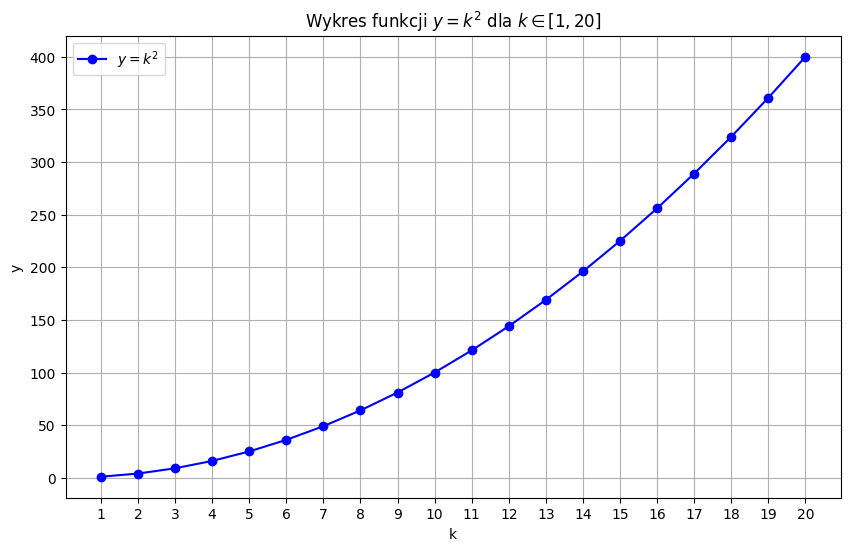

In [19]:
import matplotlib.pyplot as plt

k = list(range(1, 21))
y = [i**2 for i in k]

plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', linestyle='-', color='b', label='$y = k^2$')
plt.title(r'Wykres funkcji $y = k^2$ dla $k \in [1, 20]$')
plt.xlabel('k')
plt.ylabel('y')
plt.grid(True)
plt.xticks(k)
plt.legend()

# Zapisanie wykresu do pliku
plt.savefig('wykres.png', dpi=300)
plt.show()

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import base64

# Parametry fizyczne wahadła
g = 9.81  # przyspieszenie ziemskie [m/s^2]
L = 1.0   # długość wahadła [m]
theta0 = np.radians(45)  # kąt początkowy (45 stopni)

# Czas symulacji
t_max = 10.0
fps = 30
dt = 1.0 / fps
t = np.arange(0, t_max, dt)

# Uproszczone rozwiązanie analityczne dla małych drgań
omega = np.sqrt(g / L)
theta = theta0 * np.cos(omega * t)

# Położenie x, y końca wahadła w czasie
x = L * np.sin(theta)
y = -L * np.cos(theta)

# Przygotowanie wykresu
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.2 * L, 1.2 * L)
ax.set_ylim(-1.2 * L, 0.2 * L)
ax.set_aspect('equal')
ax.grid(True)
ax.set_title("Animacja wahadła matematycznego")

# Elementy graficzne
line, = ax.plot([], [], 'o-', lw=2, color='darkblue', markersize=10) # nić i masa

def init():
    line.set_data([], [])
    return line,

def update(frame):
    thisx = [0, x[frame]]
    thisy = [0, y[frame]]
    line.set_data(thisx, thisy)
    return line,

# Tworzenie animacji
anim = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True, interval=dt*1000)

# Zapis do pliku video.mp4 przy użyciu ffmpeg
anim.save('video.mp4', writer='ffmpeg', fps=fps, extra_args=['-vcodec', 'libx264'])
plt.close(fig)

# Odczytanie pliku wideo i zakodowanie do Base64 w celu poprawnego wyświetlenia
with open('video.mp4', 'rb') as f:
    video_bytes = f.read()
    encoded_video = base64.b64encode(video_bytes).decode('utf-8')

# Wyświetlenie wideo bezpośrednio z danych Base64
HTML(f"""
<video width="400" height="400" controls>
  <source src="data:video/mp4;base64,{encoded_video}" type="video/mp4">
  Twoja przeglądarka nie wspiera odtwarzacza wideo.
</video>
""")

In [21]:
import imageio

# Wczytanie pliku MP4 i zapisanie go jako GIF
reader = imageio.get_reader('video.mp4')
fps = reader.get_meta_data()['fps']

writer = imageio.get_writer('video.gif', fps=fps)
for frame in reader:
    writer.append_data(frame)
writer.close()

print("Plik video.gif został pomyślnie wygenerowany!")

Plik video.gif został pomyślnie wygenerowany!


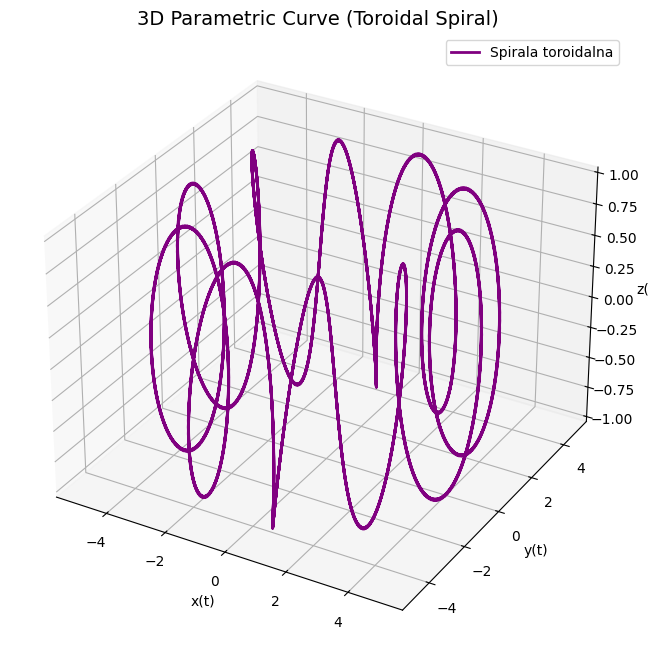

In [22]:
# Generowanie innej ciekawej trójwymiarowej krzywej parametrycznej (spirala toroidalna)
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Parametryzacja spirali toroidalnej
t = np.linspace(0, 10 * np.pi, 1000)
R = 4  # główny promień torusa
r = 1  # pomocniczy promień torusa
p = 10 # liczba obiegów

x = (R + r * np.cos(p * t)) * np.cos(t)
y = (R + r * np.cos(p * t)) * np.sin(t)
z = r * np.sin(p * t)

# Wykres 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Spirala toroidalna", color='purple', lw=2)
ax.set_title("3D Parametric Curve (Toroidal Spiral)", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

# Zapisanie wykresu do pliku graficznego
plt.savefig('parametric_curve.png', dpi=300)
plt.show()